<a href="https://colab.research.google.com/github/lipchenko/machine_learning_lipchenko/blob/main/Lipchenko_rnn_second_version_DL_16_09_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Часть A. Эксперименты с гиперпараметрами

In [ ]:
!pip install -q datasets scikit-learn seaborn tqdm matplotlib
#импортируем все библиотеки
import re
import time
import random
from collections import Counter
import os

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm
#фиксируем параметры воспроизведения для равномерного результата
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
#проверка GPU. У меня постоянно вылетал скрипт, поэтому я сделала эту проверку
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

#загрузка датасета с пары
dataset = load_dataset("fancyzhx/ag_news")
#разметка данных
train_data = list(zip(dataset['train']['label'],
                      dataset['train']['text']))
test_data  = list(zip(dataset['test']['label'],
                      dataset['test']['text']))

print(f"Обучающих примеров: {len(train_data)}")
print(f"Тестовых примеров:  {len(test_data)}")
print(f"Распределение меток: {Counter(label for label, _ in train_data)}")

#токенизируем
def tokenizer(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

def yield_tokens(data):
    for _, text in data:
        yield tokenizer(text)
#получаем словарь
def build_vocab_from_iterator(iterator, min_freq=1):
    counter = Counter()
    for tokens in iterator:
        counter.update(tokens)

    vocab = {'<pad>': 0, '<unk>': 1}

    frequent_tokens = [
        token for token, freq in counter.items()
        if freq >= min_freq and token not in ('<pad>', '<unk>')
    ]
    frequent_tokens.sort(key=lambda t: (-counter[t], t))

    vocab.update({token: idx for idx,
                  token in enumerate(frequent_tokens, start=2)})
    return vocab

#создаем класс датасета
class AGNewsDataset(torch.utils.data.Dataset):
    def __init__(self, data, text_pipeline, label_pipeline):
        self.data = data
        self.text_pipeline = text_pipeline
        self.label_pipeline = label_pipeline

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        label, text = self.data[idx]
        ids = self.text_pipeline(text)
        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(self.label_pipeline(label),
                         dtype=torch.long)
        )

def make_collate(pad_idx):
    def collate_batch(batch):
        text_list, label_list = zip(*batch)
        lengths = torch.tensor([len(t) for t in text_list],
                               dtype=torch.long)
        padded = pad_sequence(text_list, batch_first=True,
                              padding_value=pad_idx)
        labels = torch.stack(label_list)
        return padded, lengths, labels
    return collate_batch
#задаем модель RNN
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 num_layers=1, dropout=0.2, bidirectional=False, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size,
                                      embed_dim,
                                      padding_idx=pad_idx)
        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )
        rnn_out = hidden_dim * 2 if bidirectional else hidden_dim
        self.fc = nn.Linear(rnn_out, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.rnn(packed)
        if self.rnn.bidirectional:
            last_hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)
        else:
            last_hidden = hidden[-1]
        return self.fc(self.dropout(last_hidden))

#тренируем модель
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = total_correct = total_samples = 0

    for texts, lengths, labels in tqdm(loader,
                                       desc="Training",
                                       leave=False):
        texts, lengths, labels = texts.to(device), lengths.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(texts, lengths)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        preds = logits.argmax(dim=1)
        total_loss += loss.item() * labels.size(0)
        total_correct += (preds == labels).sum().item()
        total_samples += labels.size(0)

    return total_loss / total_samples, total_correct / total_samples

#оценка
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = total_correct = total_samples = 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for texts, lengths, labels in tqdm(loader, desc="Evaluating", leave=False):
            texts, lengths, labels = texts.to(device), lengths.to(device), labels.to(device)
            logits = model(texts, lengths)
            loss = criterion(logits, labels)
            preds = logits.argmax(dim=1)

            total_loss += loss.item() * labels.size(0)
            total_correct += (preds == labels).sum().item()
            total_samples += labels.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return (
        total_loss / total_samples,
        total_correct / total_samples,
        all_preds,
        all_labels
    )

Using device: cpu


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Обучающих примеров: 120000
Тестовых примеров:  7600
Распределение меток: Counter({2: 30000, 3: 30000, 1: 30000, 0: 30000})


In [ ]:
RESULTS_PATH = 'results.csv'
#данные обучения сохраняются в файл, без файла прогонять код было очень долго
CLASS_NAMES = ['World', 'Sports', 'Business', 'Sci/Tech']
#функция для прогона модели с разными параметрами
def run_experiment(
    min_freq=2,
    max_len=256,
    batch_size=64,
    embed_dim=128,
    hidden_dim=128,
    num_layers=1,
    bidirectional=False,
    learning_rate=1e-3,
    num_epochs=5,
    dropout=0.2,
    varied='baseline',
    plot=False,
    seed=SEED,
):

#настройка воспроизводимости как в первой ячейке кода
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    print(f"\n{'='*70}")
    print(f"RUN | varied={varied} | min_freq={min_freq} | max_len={max_len} | "
          f"bs={batch_size} | emb={embed_dim} | hid={hidden_dim} | "
          f"layers={num_layers} | bidir={bidirectional} | lr={learning_rate} | "
          f"epochs={num_epochs}")
    print(f"{'='*70}")

#смотрим словарь
    vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=min_freq)
    pad_idx = vocab['<pad>']
    unk_idx = vocab['<unk>']
    vocab_size = len(vocab)
    print(f"Размер словаря: {vocab_size}")


    def text_pipeline(text):
        ids = [vocab.get(tok, unk_idx) for tok in tokenizer(text)]
        if len(ids) > max_len:
            ids = ids[:max_len]
        if len(ids) == 0:
            ids = [unk_idx]
        return ids

    def label_pipeline(label):
        return label

#датасет
    train_dataset = AGNewsDataset(train_data, text_pipeline, label_pipeline)
    test_dataset  = AGNewsDataset(test_data,  text_pipeline, label_pipeline)

    collate_fn = make_collate(pad_idx)

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        collate_fn=collate_fn, num_workers=2,
        pin_memory=torch.cuda.is_available()
    )
    test_loader = DataLoader(
        test_dataset, batch_size=batch_size, shuffle=False,
        collate_fn=collate_fn, num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

#модель
    model = RNNClassifier(
        vocab_size=vocab_size,
        embed_dim=embed_dim,
        hidden_dim=hidden_dim,
        num_classes=4,
        num_layers=num_layers,
        dropout=dropout,
        bidirectional=bidirectional,
        pad_idx=pad_idx,
    ).to(device)

    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Обучаемых параметров: {num_params:,}")

#обучение модели
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss':   [], 'val_acc':   [],
        'epoch_time': [],
    }

    for epoch in range(num_epochs):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()

        train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc, _, _ = evaluate(model, test_loader, criterion)

        if torch.cuda.is_available():
            torch.cuda.synchronize()
        epoch_time = time.perf_counter() - t0

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['epoch_time'].append(epoch_time)

        print(f"Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
              f"Time: {epoch_time:.2f}s")

    avg_epoch_time = sum(history['epoch_time']) / len(history['epoch_time'])

    #финальная оценка и предсказание для анализа ошибок
    final_loss, final_acc, all_preds, all_labels = evaluate(model, test_loader, criterion)

    print(f"\nИтог: Val Loss = {final_loss:.4f}, Val Acc = {final_acc:.4f}, "
          f"Avg epoch time = {avg_epoch_time:.2f}s")

    #опциональные графики
    if plot:
        _plot_history(history)
        _plot_confusion(all_labels, all_preds)
        print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

    #сохранение строки
    row = {
        'VARIED': varied,
        'MIN_FREQ': min_freq, 'MAX_LEN': max_len, 'BATCH_SIZE': batch_size,
        'EMBED_DIM': embed_dim, 'HIDDEN_DIM': hidden_dim,
        'NUM_LAYERS': num_layers, 'BIDIRECTIONAL': bidirectional,
        'LR': learning_rate,
        'VOCAB_SIZE': vocab_size,
        'NUM_PARAMS': num_params,
        'EPOCH_TIME': avg_epoch_time,
        'VAL_LOSS': final_loss,
        'VAL_ACC': final_acc,
    }
    import pandas as pd
    pd.DataFrame([row]).to_csv(
        RESULTS_PATH, mode='a',
        header=not os.path.exists(RESULTS_PATH),
        index=False
    )

    return {
        'row': row,
        'history': history,
        'model': model,
        'vocab': vocab,
        'preds': all_preds,
        'labels': all_labels,
        'test_loader': test_loader,
        'test_data': test_data,
        'text_pipeline': text_pipeline,
    }


#вспомогательные функции для графиков
def _plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
    axes[0].plot(history['val_loss'],   label='Val Loss',   marker='s')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].set_title('Loss Curve'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history['train_acc'], label='Train Acc', marker='o')
    axes[1].plot(history['val_acc'],   label='Val Acc',   marker='s')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Accuracy Curve'); axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def _plot_confusion(all_labels, all_preds):
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.title('Confusion Matrix (Test Set)')
    plt.tight_layout(); plt.show()


RUN | varied=baseline | min_freq=2 | max_len=256 | bs=64 | emb=128 | hid=128 | layers=1 | bidir=False | lr=0.001 | epochs=5
Размер словаря: 44138
Обучаемых параметров: 5,683,204


Epoch 1/5 | Train Loss: 0.8994 | Train Acc: 0.6175 | Val Loss: 0.6349 | Val Acc: 0.7782 | Time: 369.96s


Epoch 2/5 | Train Loss: 0.6062 | Train Acc: 0.7879 | Val Loss: 0.5586 | Val Acc: 0.8082 | Time: 395.34s


Epoch 3/5 | Train Loss: 0.5017 | Train Acc: 0.8366 | Val Loss: 0.4737 | Val Acc: 0.8539 | Time: 401.93s


Epoch 4/5 | Train Loss: 0.4455 | Train Acc: 0.8577 | Val Loss: 0.4328 | Val Acc: 0.8713 | Time: 397.73s


Epoch 5/5 | Train Loss: 0.4037 | Train Acc: 0.8741 | Val Loss: 0.4072 | Val Acc: 0.8768 | Time: 396.00s



Итог: Val Loss = 0.4072, Val Acc = 0.8768, Avg epoch time = 392.19s


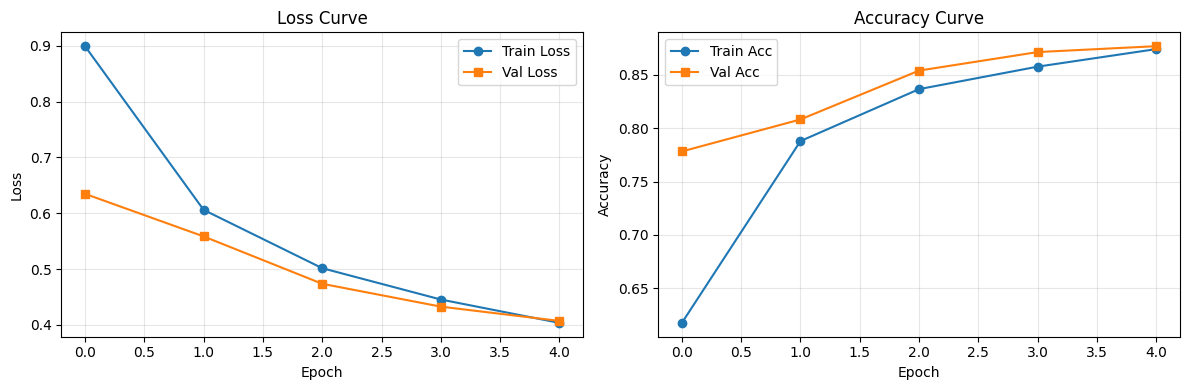

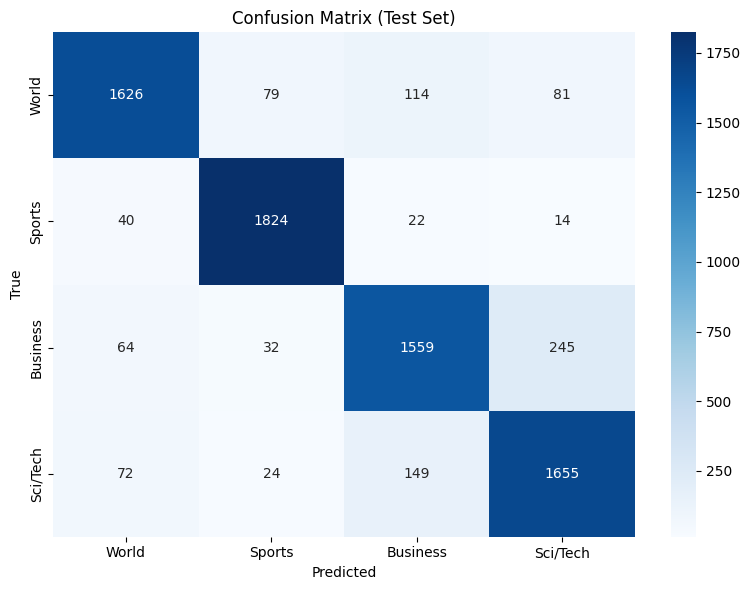

              precision    recall  f1-score   support

       World       0.90      0.86      0.88      1900
      Sports       0.93      0.96      0.95      1900
    Business       0.85      0.82      0.83      1900
    Sci/Tech       0.83      0.87      0.85      1900

    accuracy                           0.88      7600
   macro avg       0.88      0.88      0.88      7600
weighted avg       0.88      0.88      0.88      7600



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


RUN | varied=MIN_FREQ | min_freq=5 | max_len=256 | bs=64 | emb=128 | hid=128 | layers=1 | bidir=False | lr=0.001 | epochs=5
Размер словаря: 27831
Обучаемых параметров: 3,595,908


Epoch 1/5 | Train Loss: 0.8945 | Train Acc: 0.6087 | Val Loss: 0.7804 | Val Acc: 0.7274 | Time: 270.98s


...

Epoch 4/5 | Train Loss: 0.2925 | Train Acc: 0.9021 | Val Loss: 0.3328 | Val Acc: 0.8928 | Time: 530.22s


Epoch 5/5 | Train Loss: 0.2646 | Train Acc: 0.9115 | Val Loss: 0.3117 | Val Acc: 0.9005 | Time: 528.16s



Итог: Val Loss = 0.3117, Val Acc = 0.9005, Avg epoch time = 523.35s


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#здесь проверяю остался ли старый csv или новый, чтобы не было ошибок после итерации
import os
if os.path.exists('results.csv'):
    os.remove('results.csv')
    print("Старый results.csv удалён")

#бейзлайн для запуска графика
baseline_result = run_experiment(
    min_freq=2, max_len=256, batch_size=64,
    embed_dim=128, hidden_dim=128, num_layers=1,
    bidirectional=False, learning_rate=1e-3,
    num_epochs=5, varied='baseline', plot=True
)

from google.colab import files
files.download('results.csv')

#бейзлайн для параметра MIN_FREQUENCY
for mf in [5, 10]:
    run_experiment(
        min_freq=mf, max_len=256, batch_size=64,
        embed_dim=128, hidden_dim=128, num_layers=1,
        bidirectional=False, learning_rate=1e-3,
        num_epochs=5, varied='MIN_FREQ', plot=False
    )
files.download('results.csv')

#бейзлайн для параметра MAX_LEN
for ml in [128, 512]:
    run_experiment(
        min_freq=2, max_len=ml, batch_size=64,
        embed_dim=128, hidden_dim=128, num_layers=1,
        bidirectional=False, learning_rate=1e-3,
        num_epochs=5, varied='MAX_LEN', plot=False
    )
files.download('results.csv')

# для BATCH_SIZE
for bs in [32, 128]:
    run_experiment(
        min_freq=2, max_len=256, batch_size=bs,
        embed_dim=128, hidden_dim=128, num_layers=1,
        bidirectional=False, learning_rate=1e-3,
        num_epochs=5, varied='BATCH_SIZE', plot=False
    )
files.download('results.csv')

# для NUM_LAYERS в значении 2
run_experiment(
    min_freq=2, max_len=256, batch_size=64,
    embed_dim=128, hidden_dim=128, num_layers=2,
    bidirectional=False, learning_rate=1e-3,
    num_epochs=5, varied='NUM_LAYERS', plot=False
)
files.download('results.csv')

# для BIDIRECTIONAL в значении True
run_experiment(
    min_freq=2, max_len=256, batch_size=64,
    embed_dim=128, hidden_dim=128, num_layers=1,
    bidirectional=True, learning_rate=1e-3,
    num_epochs=5, varied='BIDIRECTIONAL', plot=False
)
files.download('results.csv')

['VARIED', 'MIN_FREQ', 'MAX_LEN', 'BATCH_SIZE', 'EMBED_DIM', 'HIDDEN_DIM', 'NUM_LAYERS', 'BIDIRECTIONAL', 'LR', 'VOCAB_SIZE', 'NUM_PARAMS', 'EPOCH_TIME', 'VAL_LOSS', 'VAL_ACC']
base_acc = 0.8768


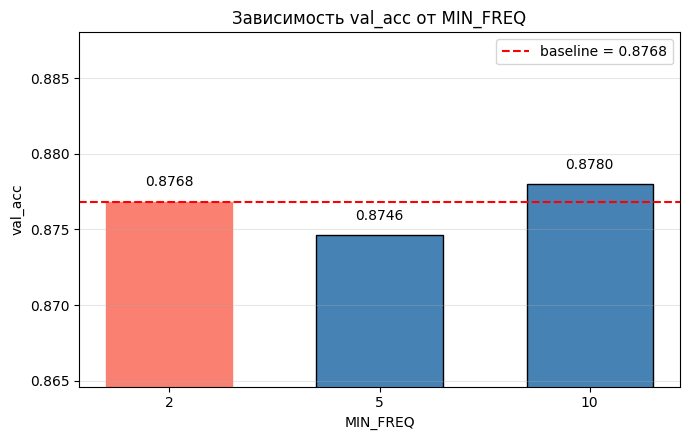

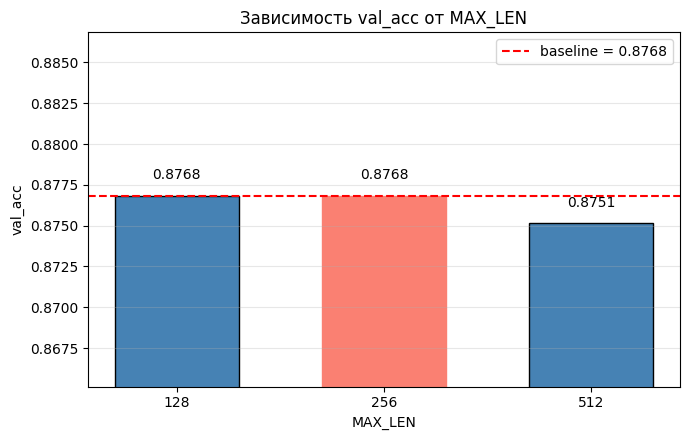

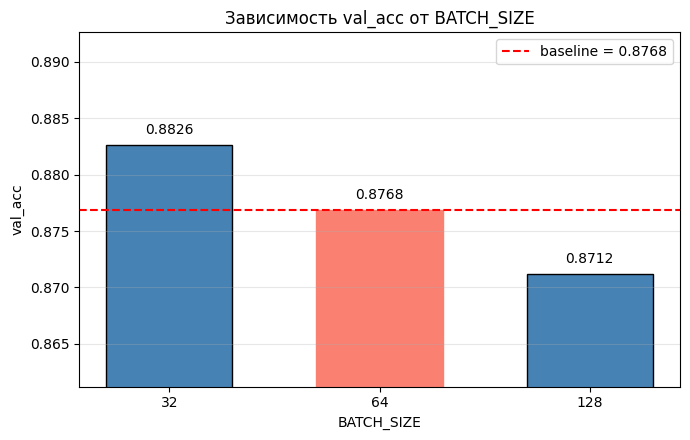

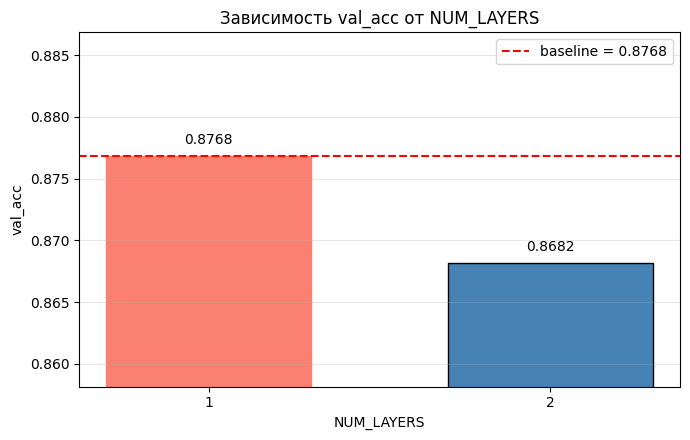

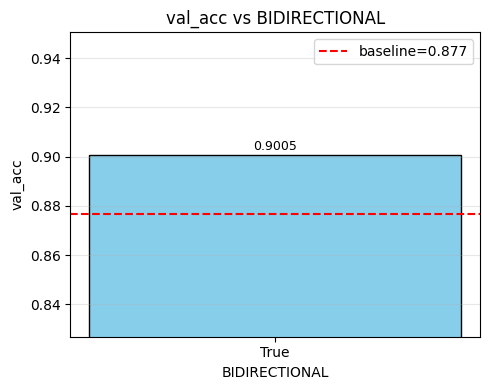

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('results.csv')
print(df.columns.tolist())

#задаем значение бейзлайн accuracy, рисуем его красной линией на графиках
base_rows = df.loc[df['VARIED'] == 'baseline', 'VAL_ACC']
if len(base_rows) == 0:
    print("нет бейзлайн, беру первую строку")
    base_acc = df['VAL_ACC'].iloc[0]
else:
    base_acc = base_rows.values[0]
print(f"base_acc = {base_acc:.4f}")


def plot_param_bar(df, param, base_acc, xlabels=None,
                   baseline_value=None, color='steelblue'):
    sub = df[df['VARIED'] == param].sort_values(param)
    if sub.empty:
        print(f"Нет данных для {param}"); return

    #здесь вручную ставим точку на графике с бейзлайн, потому что на графиках не отображались все параметры
    #в файле csv два раза обозначается параметр min_freq=2, графики выходили грязные
    if baseline_value is not None:
        base_row = df[df['VARIED'] == 'baseline'].iloc[0]
        base_point = pd.DataFrame([{
            param: baseline_value,
            'VAL_ACC': base_row['VAL_ACC'],
        }])
        sub = pd.concat([sub[[param, 'VAL_ACC']], base_point], ignore_index=True)
        sub = sub.sort_values(param).drop_duplicates(subset=[param])

    x = xlabels if xlabels else sub[param].astype(str).tolist()

    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(x, sub['VAL_ACC'], color=color, edgecolor='black', width=0.6)

    #красим столбики другим цыетом и добавляем значения столбиков
    if baseline_value is not None:
        base_idx = sub[param].astype(str).tolist().index(str(baseline_value))
        bars[base_idx].set_color('salmon')

    for bar, acc in zip(bars, sub['VAL_ACC']):
        ax.text(bar.get_x() + bar.get_width()/2, acc + 0.001,
                f'{acc:.4f}', ha='center', fontsize=10)

    ax.axhline(base_acc, color='red', linestyle='--',
               linewidth=1.5, label=f'baseline = {base_acc:.4f}')

    ax.set_xlabel(param)
    ax.set_ylabel('val_acc')
    ax.set_title(f'Зависимость val_acc от {param}')

    y_min = min(sub['VAL_ACC'].min(), base_acc) - 0.01
    y_max = max(sub['VAL_ACC'].max(), base_acc) + 0.01
    ax.set_ylim(y_min, y_max)
    ax.grid(axis='y', alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.savefig(f'val_acc_{param.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()


#вызовы с разными параметрами
plot_param_bar(df, 'MIN_FREQ',      base_acc, baseline_value=2)
plot_param_bar(df, 'MAX_LEN',       base_acc, baseline_value=256)
plot_param_bar(df, 'BATCH_SIZE',    base_acc, baseline_value=64)
plot_param_bar(df, 'NUM_LAYERS',    base_acc, baseline_value=1)

#отдельно вызываем learning rate, потому что у нас здесь есть xlabels
if 'LEARNING_RATE' in df['VARIED'].values:
    plot_param_bar(df, 'LEARNING_RATE', base_acc,
                   xlabels=['1e-3', '5e-4', '1e-4'],
                   baseline_value=1e-3)

#отдельный график для BIDIRECTIONAL с булевым значением
plot_binary(df, 'BIDIRECTIONAL', base_acc)

#Часть B. Анализ ошибок

In [ ]:
def get_errors(model, loader, test_data, id2label, device, n=10):
    model.eval()
    errors = []
    idx = 0

    with torch.no_grad():
        for texts, lengths, labels in loader:
            texts = texts.to(device)
            lengths = lengths.to(device)

            logits = model(texts, lengths)
            preds = logits.argmax(dim=1).cpu().numpy()
            labels_np = labels.numpy()

            for p, y in zip(preds, labels_np):
                if p != y:
                    text = test_data[idx][1]
                    errors.append({
                        'idx': idx,
                        'true': id2label[y],
                        'pred': id2label[p],
                        'n_words': len(text.split()),
                        'text': text[:200],
                    })
                    if len(errors) >= n:
                        return pd.DataFrame(errors)
                idx += 1

    return pd.DataFrame(errors)

In [ ]:
id2label = {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Sci/Tech'}

In [ ]:
errors_df = get_errors(
    model=baseline_result['model'],
    loader=baseline_result['test_loader'],
    test_data=baseline_result['test_data'],
    id2label=id2label,
    device=device,
    n=10,
)

errors_df[['idx', 'true', 'pred', 'n_words', 'text']]

,idx,true,pred,n_words,text
0,3,Sci/Tech,World,55,Prediction Unit Helps Forecast Wildfires (AP) ...
1,13,Sci/Tech,Sports,23,Super ant colony hits Australia A giant 100km ...
2,15,Sci/Tech,Business,21,Teenage T. rex's monster growth Tyrannosaurus ...
3,23,Sci/Tech,Business,67,Some People Not Eligible to Get in on Google I...
4,24,Sci/Tech,World,40,Rivals Try to Turn Tables on Charles Schwab By...
5,35,World,Sci/Tech,64,"Frail Pope Celebrates Mass at Lourdes LOURDES,..."
6,36,World,Business,24,Venezuela Prepares for Chavez Recall Vote Supp...
7,47,Sci/Tech,Business,50,Dell Exits Low-End China Consumer PC Market H...
8,56,World,Business,41,India's Tata expands regional footprint via Na...
9,65,Sci/Tech,Business,25,Indian state rolls out wireless broadband Gove...


#*Гипотезы*

1. Специальные термины. Во втором примере модель предсказывает тему World, хотя на самом деле это Sci/Tech тема, из-за экологического термина Forecast Wildfires.
2. Смешанные тематики. В первом тексте используются термины, которые используются в теме и политики и бизнеса (pension, workers).

#*Идеи для улучшения:*
1. Использовать subword токенизацию, а не word-level.Word level не распознает редкие термины из новостных статей.
2. Модель путает тематики, можно добавить синтетические данные с темами, которые путает модель. Модель увидит больше смешанных примеров и начнет лучше их размечать.

#Часть C. Улучшение архитектуры (использовала скрипт из нашего туториала)

In [ ]:
!pip install -q datasets scikit-learn seaborn tqdm matplotlib

In [ ]:
import re
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence
)

from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print(f"Using device: {device}")

Using device: cpu


## 2. Загрузка данных

In [ ]:
dataset = load_dataset("fancyzhx/ag_news")

print(dataset)
print("\nПример:", dataset['train'][0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Пример: {'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [ ]:
train_data = list(zip(
    dataset['train']['label'],
    dataset['train']['text']
))

test_data = list(zip(
    dataset['test']['label'],
    dataset['test']['text']
))

print(f"Обучающих примеров: {len(train_data)}")
print(f"Тестовых примеров: {len(test_data)}")

print(
    f"\nРаспределение меток: "
    f"{Counter(label for label, _ in train_data)}"
)

Обучающих примеров: 120000
Тестовых примеров: 7600

Распределение меток: Counter({2: 30000, 3: 30000, 1: 30000, 0: 30000})


## 3. Визуализация данных

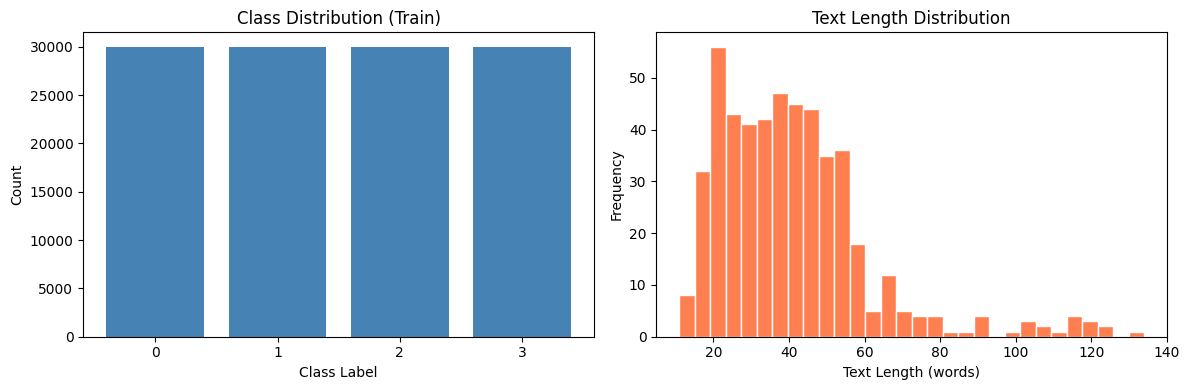

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = [label for label, _ in train_data]
label_counts = Counter(labels)

axes[0].bar(
    label_counts.keys(),
    label_counts.values(),
    color='steelblue'
)

axes[0].set_xlabel('Class Label')
axes[0].set_ylabel('Count')
axes[0].set_title('Class Distribution (Train)')
axes[0].set_xticks([0, 1, 2, 3])

lengths = [
    len(text.split())
    for _, text in train_data[:500]
]

axes[1].hist(
    lengths,
    bins=30,
    color='coral',
    edgecolor='white'
)

axes[1].set_xlabel('Text Length (words)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Text Length Distribution')

plt.tight_layout()
plt.show()

In [ ]:
print("\n=== Примеры ===")

for i in range(3):
    label, text = train_data[i]
    print(f"[Label {label}] {text[:150]}...")


=== Примеры ===
[Label 2] Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again....
[Label 2] Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and ...
[Label 2] Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expecte...


## 4. Токенизация и словарь

In [ ]:
def tokenizer(text):
    """
    Простой токенизатор без torchtext.
    Приводит текст к нижнему регистру и отделяет пунктуацию.
    """
    return re.findall(
        r"\w+|[^\w\s]",
        text.lower()
    )


def yield_tokens(data):
    for _, text in data:
        yield tokenizer(text)

In [ ]:
def build_vocab_from_iterator(iterator, min_freq=1):
    counter = Counter()

    for tokens in iterator:
        counter.update(tokens)

    # Индексы специальных токенов:
    # <pad> = 0
    # <unk> = 1
    vocab = {
        '<pad>': 0,
        '<unk>': 1,
    }

    frequent_tokens = [
        token
        for token, frequency in counter.items()
        if frequency >= min_freq
        and token not in ('<pad>', '<unk>')
    ]

    # Сначала частые слова, затем алфавитный порядок
    frequent_tokens.sort(
        key=lambda token: (-counter[token], token)
    )

    vocab.update({
        token: index
        for index, token in enumerate(
            frequent_tokens,
            start=2
        )
    })

    return vocab

In [ ]:
# ============================================
# Задание 1: параметры построения словаря
# Попробуйте min_freq = 2 или 10. Как меняются размер словаря и качество модели?
# Почему редкие слова могут как помогать, так и мешать?
# ============================================
MIN_FREQ = 5  # <-- меняйте здесь

# Сначала строим словарь только из реальных токенов
vocab = build_vocab_from_iterator(
    yield_tokens(train_data),
    min_freq=MIN_FREQ
)

# Добавляем специальные токены вручную
# Порядок важен: <pad> должен быть первым (индекс 0), <unk> — вторым (индекс 1)

# Устанавливаем токен по умолчанию для неизвестных слов
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

print(f"Размер словаря: {len(vocab)}")
print(f"PAD_IDX = {PAD_IDX}, UNK_IDX = {UNK_IDX}")

Размер словаря: 27831
PAD_IDX = 0, UNK_IDX = 1


## 5. Предобработка и Dataset

In [ ]:
# ============================================
# Задание 2: длина последовательности (обрезка)
# Попробуйте MAX_LEN = 128, 256, 512. Как меняются скорость обучения и точность?
# Почему у RNN может не быть выигрыша от очень длинных последовательностей?
# ============================================
MAX_LEN = 256  # <-- меняйте здесь

In [ ]:
def text_pipeline(text):
    tokens = tokenizer(text)

    ids = [
        vocab.get(token, UNK_IDX)
        for token in tokens
    ]

    if len(ids) > MAX_LEN:
        ids = ids[:MAX_LEN]

    # На случай пустого текста
    if len(ids) == 0:
        ids = [UNK_IDX]

    return ids


def label_pipeline(label):
    return label

In [ ]:
class AGNewsDataset(torch.utils.data.Dataset):
    def __init__(
        self,
        data,
        text_pipeline,
        label_pipeline
    ):
        self.data = data
        self.text_pipeline = text_pipeline
        self.label_pipeline = label_pipeline

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        label, text = self.data[idx]

        ids = self.text_pipeline(text)

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(
                self.label_pipeline(label),
                dtype=torch.long
            )
        )

In [ ]:
def collate_batch(batch):
    text_list, label_list = zip(*batch)

    lengths = torch.tensor(
        [len(text) for text in text_list],
        dtype=torch.long
    )

    padded = pad_sequence(
        text_list,
        batch_first=True,
        padding_value=PAD_IDX
    )

    labels = torch.stack(label_list)

    return padded, lengths, labels

In [ ]:
train_dataset = AGNewsDataset(
    train_data,
    text_pipeline,
    label_pipeline
)

test_dataset = AGNewsDataset(
    test_data,
    text_pipeline,
    label_pipeline
)

## 6. DataLoader

In [ ]:
# ============================================
# Задание 3: размер батча
# Попробуйте BATCH_SIZE = 32, 64, 128. Как это влияет на стабильность обучения и скорость?
# Документация: https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader
# ============================================
BATCH_SIZE = 64  # <-- меняйте здесь

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print(
    f"Количество батчей в обучении: "
    f"{len(train_loader)}"
)

Количество батчей в обучении: 1875


## 7. RNN-модель

In [ ]:
class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2,
        bidirectional=False
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.GRU(
        input_size=embed_dim,
        hidden_size=hidden_dim,
        num_layers=num_layers,
        batch_first=True,
        dropout=dropout if num_layers > 1 else 0,
        bidirectional=bidirectional
    )

        rnn_output_dim = (
            hidden_dim * 2
            if bidirectional
            else hidden_dim
        )

        self.fc = nn.Linear(
            rnn_output_dim,
            num_classes
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(
            self.embedding(x)
        )

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        if self.rnn.bidirectional:
            last_hidden = torch.cat(
                [hidden[-2], hidden[-1]],
                dim=1
            )
        else:
            last_hidden = hidden[-1]

        output = self.fc(
            self.dropout(last_hidden)
        )

        return output

In [ ]:
# ============================================
# Задание 4: гиперпараметры модели
# Попробуйте разные комбинации и посмотрите на точность на валидации:
#   EMBED_DIM: 64, 128, 256
#   HIDDEN_DIM: 64, 128, 256
#   NUM_LAYERS: 1, 2
#   BIDIRECTIONAL: True / False
# Как размер скрытого состояния связан с числом параметров и качеством?
# ============================================
EMBED_DIM = 128       # <-- меняйте здесь
HIDDEN_DIM = 128      # <-- меняйте здесь
NUM_LAYERS = 1        # <-- меняйте здесь
BIDIRECTIONAL = False # <-- меняйте здесь (True/False)
DROPOUT = 0.2

In [ ]:
model = RNNClassifier(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=4,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=BIDIRECTIONAL
).to(device)

print(model)

print(
    f"Количество обучаемых параметров: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

RNNClassifier(
  (embedding): Embedding(27831, 128, padding_idx=0)
  (rnn): GRU(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=4, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)
Количество обучаемых параметров: 3,661,956


## 8. Обучение и проверка

In [ ]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for texts, lengths, labels in tqdm(
        loader,
        desc="Training"
    ):
        texts = texts.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(texts, lengths)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        predictions = logits.argmax(dim=1)

        total_loss += (
            loss.item() * labels.size(0)
        )

        total_correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [ ]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for texts, lengths, labels in tqdm(
            loader,
            desc="Evaluating"
        ):
            texts = texts.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            logits = model(texts, lengths)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            total_loss += (
                loss.item() * labels.size(0)
            )

            total_correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            total_samples += labels.size(0)

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return (
        total_loss / total_samples,
        total_correct / total_samples,
        all_preds,
        all_labels
    )

In [ ]:
# ============================================
# Задание 5: параметры оптимизатора
# Попробуйте LEARNING_RATE = 1e-3, 5e-4, 1e-4.
# Как скорость обучения влияет на сходимость и стабильность?
# Документация: https://pytorch.org/docs/stable/optim.html#torch.optim.Adam
# ============================================
LEARNING_RATE = 1e-3  # <-- меняйте здесь
NUM_EPOCHS = 5        # <-- меняйте здесь

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'epoch_time': []
}

for epoch in range(NUM_EPOCHS):
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    train_loss, train_acc = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_acc, _, _ = evaluate(
        model,
        test_loader,
        criterion
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time


    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['epoch_time'].append(epoch_time)


    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )
#выводим время эпохи
avg_epoch_time = sum(history['epoch_time']) / len(history['epoch_time'])
print(f"\nAverage epoch time: {avg_epoch_time:.2f}s")

Evaluating: 100%|██████████| 119/119 [00:03<00:00, 33.74it/s]


Epoch 1/5 | Train Loss: 0.5304 | Train Acc: 0.7930 | Val Loss: 0.2964 | Val Acc: 0.8968 | Time: 496.34s


Evaluating: 100%|██████████| 119/119 [00:03<00:00, 33.56it/s]


Epoch 2/5 | Train Loss: 0.2685 | Train Acc: 0.9074 | Val Loss: 0.2534 | Val Acc: 0.9116 | Time: 494.82s


Evaluating: 100%|██████████| 119/119 [00:04<00:00, 24.63it/s]


Epoch 3/5 | Train Loss: 0.2151 | Train Acc: 0.9254 | Val Loss: 0.2401 | Val Acc: 0.9201 | Time: 503.52s


Evaluating: 100%|██████████| 119/119 [00:04<00:00, 28.03it/s]


Epoch 4/5 | Train Loss: 0.1803 | Train Acc: 0.9379 | Val Loss: 0.2311 | Val Acc: 0.9245 | Time: 492.50s


Evaluating: 100%|██████████| 119/119 [00:04<00:00, 28.07it/s]

Epoch 5/5 | Train Loss: 0.1567 | Train Acc: 0.9454 | Val Loss: 0.2423 | Val Acc: 0.9208 | Time: 490.44s

Average epoch time: 495.53s


## 9. Кривые обучения

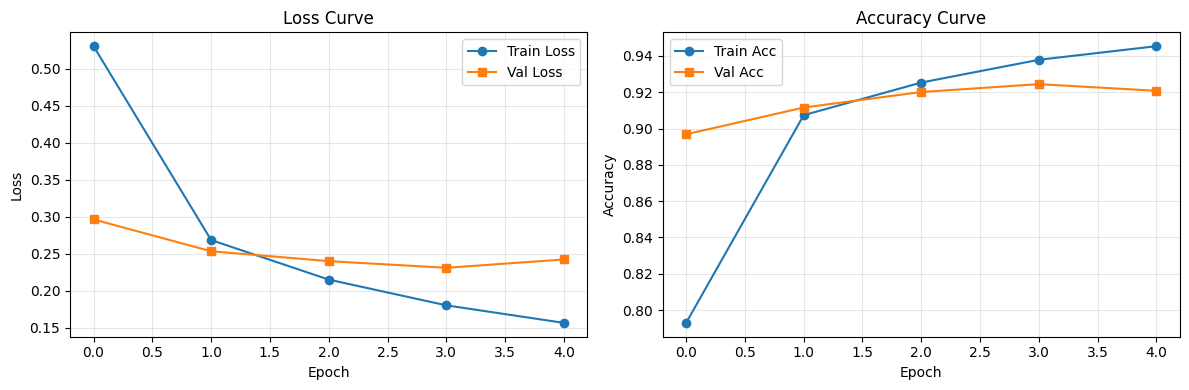

In [ ]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    history['train_loss'],
    label='Train Loss',
    marker='o'
)

axes[0].plot(
    history['val_loss'],
    label='Val Loss',
    marker='s'
)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history['train_acc'],
    label='Train Acc',
    marker='o'
)

axes[1].plot(
    history['val_acc'],
    label='Val Acc',
    marker='s'
)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Curve')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Матрица ошибок и classification report

In [ ]:
val_loss, val_acc, all_preds, all_labels = evaluate(
    model,
    test_loader,
    criterion
)

print(f"Test loss: {val_loss:.4f}")
print(f"Test accuracy: {val_acc:.4f}")

Evaluating: 100%|██████████| 119/119 [00:07<00:00, 15.49it/s]

Test loss: 0.2423
Test accuracy: 0.9208


In [ ]:
class_names = [
    'World',
    'Sports',
    'Business',
    'Sci/Tech'
]

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

       World       0.95      0.90      0.93      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.88      0.90      0.89      1900
    Sci/Tech       0.89      0.91      0.90      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



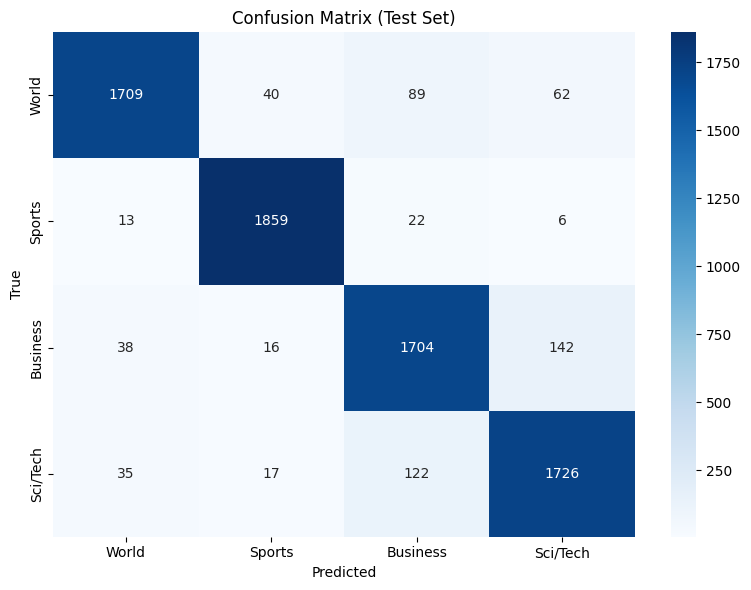

In [ ]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

In [ ]:
print(f"""
Размер словаря: {len(vocab)}
Количество обучаемых параметров: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}
Val Loss: {val_loss:.4f}
Val Acc: {val_acc:.4f}
Время эпохи: {epoch_time:.2f}s
Average epoch time: {avg_epoch_time:.2f}s

""")


Размер словаря: 27831
Количество обучаемых параметров: 3,661,956
Val Loss: 0.2423
Val Acc: 0.9208
Время эпохи: 490.44s
Average epoch time: 495.53s




In [2]:
df = pd.DataFrame([
    #       словарь, параметры, время эпохи, vloss, vacc
    ('RNN',         44138, 5683204, 392.19, 0.4072, 0.8768),
    ('GRU',         27831,   3661956,     526.54,    0.2721,    0.9255),
], columns=['MODEL', 'VOCAB_SIZE', 'NUM_PARAMS', 'EPOCH_TIME', 'VAL_LOSS', 'VAL_ACC'])

df

,MODEL,VOCAB_SIZE,NUM_PARAMS,EPOCH_TIME,VAL_LOSS,VAL_ACC
0,RNN,44138,5683204,392.19,0.4072,0.8768
1,GRU,27831,3661956,526.54,0.2721,0.9255


##Почему GRU часто работает лучше на длинных последовательностях?
В таблице мы видим, что архитектура GRU увеличила Accuracy и уменьшила метрику Loss. GRU часто оказывается лучше RNN, потому что у данной архитектуры есть параметры update gate и reset. Из-за этого GRU сохраняет контекст текста. В RNN на длинных текстах градиент затухает, модель забывает контекст.

##Часть D. Мини-исследование

In [ ]:
val_loss, val_acc, all_preds, all_labels = evaluate(
    model, test_loader, criterion
)
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

Evaluating: 100%|██████████| 119/119 [00:03<00:00, 31.14it/s]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# длины в словах
texts = [t for _, t in test_data]
word_lengths = np.array([len(t.split()) for t in texts])

print(f"Мин. длина: {word_lengths.min()} слов")
print(f"Макс. длина: {word_lengths.max()} слов")
print(f"Средняя: {word_lengths.mean():.1f} слов")
print(f"Медиана: {np.median(word_lengths):.0f} слов")

#Разделение данных
bins = [0, 25, 35, 50, 10**9]
labels = ['0–25', '26–35', '36–50', '50+']

rows = []
for i in range(len(bins) - 1):
    lo, hi = bins[i], bins[i+1]
    mask = (word_lengths >= lo) & (word_lengths < hi)
    n = mask.sum()
    if n == 0:
        rows.append({'group': labels[i], 'n': 0, 'accuracy': np.nan})
        continue
    acc = (all_preds[mask] == all_labels[mask]).mean()
    rows.append({'group': labels[i], 'n': int(n), 'accuracy': float(acc)})

df_len = pd.DataFrame(rows)
df_len

,group,n,accuracy
0,0–25,511,0.831703
1,26–35,2352,0.920068
2,36–50,4133,0.933946
3,50+,604,0.908940


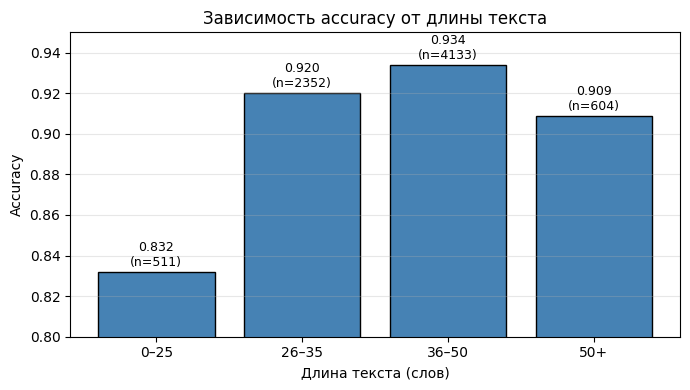

In [ ]:
plt.figure(figsize=(7, 4))
bars = plt.bar(df_len['group'], df_len['accuracy'],
               color='steelblue', edgecolor='black')

for bar, (_, r) in zip(bars, df_len.iterrows()):
    if np.isnan(r['accuracy']):
        continue
    plt.text(bar.get_x() + bar.get_width()/2,
             r['accuracy'] + 0.003,
             f"{r['accuracy']:.3f}\n(n={r['n']})",
             ha='center', fontsize=9)

plt.xlabel('Длина текста (слов)')
plt.ylabel('Accuracy')
plt.title('Зависимость accuracy от длины текста')
plt.ylim(0.80, 0.95)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('accuracy_by_length.png', dpi=150, bbox_inches='tight')
plt.show()

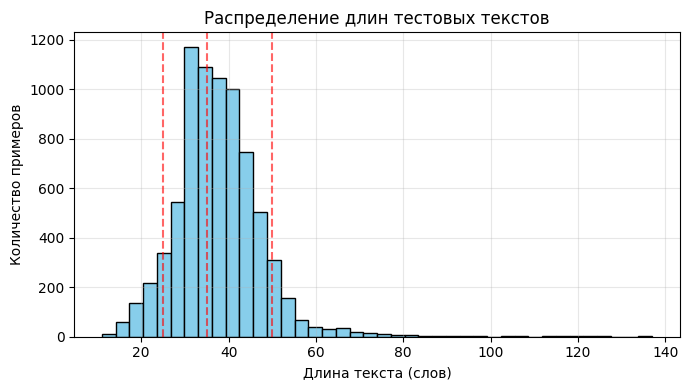

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(word_lengths, bins=40, color='skyblue', edgecolor='black')
for b in bins[1:-1]:
    plt.axvline(b, color='red', linestyle='--', alpha=0.6)
plt.xlabel('Длина текста (слов)')
plt.ylabel('Количество примеров')
plt.title('Распределение длин тестовых текстов')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##Подтверждение гипотезы
Гипотеза "чем длиннее текст, тем лучше модель его классифицирует" подтверждается частично. На моем графике Accuracy для текстов 50+ уменьшается. Возможно, это связано с неравномерной выборкой тестовых данных, текстов 50+ значительно меньше. Также это могло произойти из-за смешанной тематики в длинных новостях, где используется разная лексика.